
# Los Angeles Dodgers Attendance Analysis and Recommendation

**Student:** Anil Bammidi  
**Dataset:** `dodgers-2022.csv`  
**Objective:** Use the Dodgers home game data to recommend actions management can take to improve attendance.

## Business question

The front office wants to know what factors appear to drive attendance and what actions are most likely to increase turnout.

## Analytical approach

This notebook follows a simple story:

1. Load and inspect the data.
2. Explore attendance patterns by calendar timing, promotions, opponents, and weather.
3. Fit a multiple linear regression model to separate the effects of promotions from timing and opponent effects.
4. Translate the findings into practical recommendations for management.

## Assumptions and limitations

- The file appears to contain one season of Dodgers home games (81 observations).
- Attendance is treated as the outcome to explain.
- Promotions are represented by four yes/no columns: cap, shirt, fireworks, and bobblehead.
- Important factors such as ticket prices, team record at game time, star player availability, school schedules, and marketing spend are **not** included in the dataset.
- Because of the missing variables above, this analysis should be used as a decision aid rather than a perfect causal study.


In [5]:

# Import the libraries needed for the analysis.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read the Dodgers attendance dataset.
df = pd.read_csv("dodgers-2022.csv")

# Display the first few rows to understand the structure.
df.head()


,month,day,attend,day_of_week,opponent,temp,skies,day_night,cap,shirt,fireworks,bobblehead
0,APR,10,56000,Tuesday,Pirates,67,Clear,Day,NO,NO,NO,NO
1,APR,11,29729,Wednesday,Pirates,58,Cloudy,Night,NO,NO,NO,NO
2,APR,12,28328,Thursday,Pirates,57,Cloudy,Night,NO,NO,NO,NO
3,APR,13,31601,Friday,Padres,54,Cloudy,Night,NO,NO,YES,NO
4,APR,14,46549,Saturday,Padres,57,Cloudy,Night,NO,NO,NO,NO


Matplotlib is building the font cache; this may take a moment.


,month,day,attend,day_of_week,opponent,temp,skies,day_night,cap,shirt,fireworks,bobblehead
0,APR,10,56000,Tuesday,Pirates,67,Clear,Day,NO,NO,NO,NO
1,APR,11,29729,Wednesday,Pirates,58,Cloudy,Night,NO,NO,NO,NO
2,APR,12,28328,Thursday,Pirates,57,Cloudy,Night,NO,NO,NO,NO
3,APR,13,31601,Friday,Padres,54,Cloudy,Night,NO,NO,YES,NO
4,APR,14,46549,Saturday,Padres,57,Cloudy,Night,NO,NO,NO,NO


In [6]:

# Check the number of rows and columns, data types, and missing values.
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values by column:")
print(df.isna().sum())


Shape: (81, 12)

Data types:
month          object
day             int64
attend          int64
day_of_week    object
opponent       object
temp            int64
skies          object
day_night      object
cap            object
shirt          object
fireworks      object
bobblehead     object
dtype: object

Missing values by column:
month          0
day            0
attend         0
day_of_week    0
opponent       0
temp           0
skies          0
day_night      0
cap            0
shirt          0
fireworks      0
bobblehead     0
dtype: int64



## Initial observations

The dataset is clean and compact, with 81 home games and no obvious missing values. That means we can move directly into exploration without a major data-cleaning phase.


In [7]:

# Summary statistics for attendance and temperature.
df[['attend', 'temp']].describe().round(2)


,attend,temp
count,81.00,81.00
mean,41040.07,73.15
std,8297.54,8.32
min,24312.00,54.00
25%,34493.00,67.00
50%,40284.00,73.00
75%,46588.00,79.00
max,56000.00,95.00


In [8]:

# Average attendance by day of week.
attendance_by_day = (
    df.groupby('day_of_week', as_index=False)['attend']
      .mean()
      .sort_values('attend', ascending=False)
)

attendance_by_day


,day_of_week,attend
5,Tuesday,47741.230769
2,Saturday,43072.923077
3,Sunday,42268.846154
4,Thursday,40407.400000
0,Friday,40116.923077
6,Wednesday,37585.166667
1,Monday,34965.666667


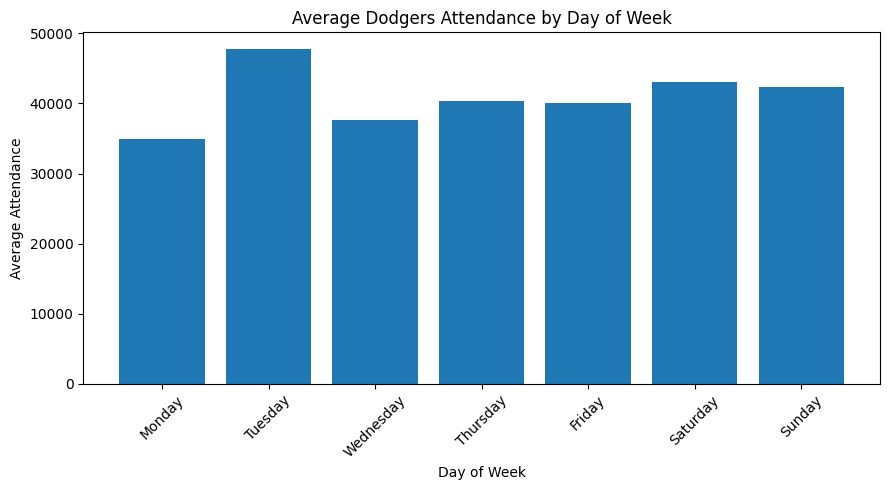

In [9]:

# Plot average attendance by day of week.
ordered_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_plot = (
    df.groupby('day_of_week')['attend']
      .mean()
      .reindex(ordered_days)
)

plt.figure(figsize=(9, 5))
plt.bar(day_plot.index, day_plot.values)
plt.title('Average Dodgers Attendance by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Attendance')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Story from the calendar pattern

Attendance varies a lot by day of week. In this dataset, **Monday and Wednesday** are among the weakest attendance days, while **Tuesday, Saturday, and Sunday** are stronger. This suggests that calendar timing matters and that the team should focus on boosting weaker weekdays rather than relying only on already-strong dates.


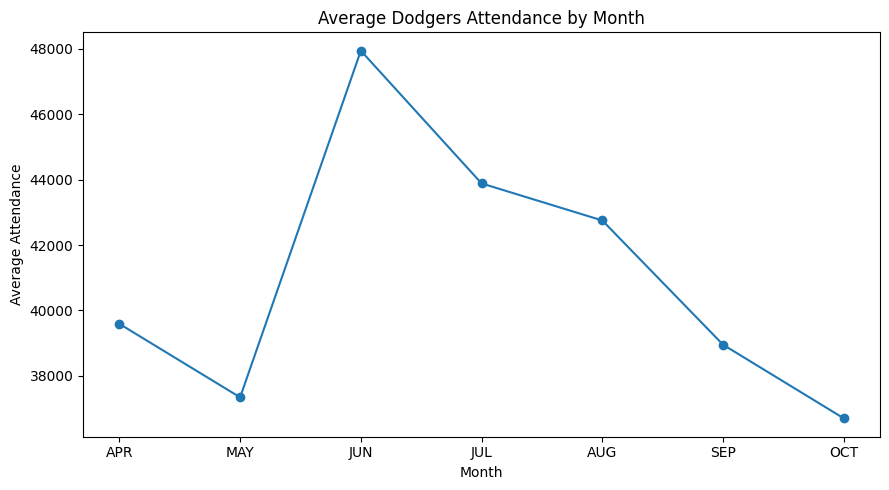

month
APR    39591.9
MAY    37345.7
JUN    47940.4
JUL    43884.2
AUG    42751.5
SEP    38955.1
OCT    36703.7
Name: attend, dtype: float64

In [10]:

# Average attendance by month.
month_order = ['APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT']
attendance_by_month = (
    df.groupby('month')['attend']
      .mean()
      .reindex(month_order)
)

plt.figure(figsize=(9, 5))
plt.plot(attendance_by_month.index, attendance_by_month.values, marker='o')
plt.title('Average Dodgers Attendance by Month')
plt.xlabel('Month')
plt.ylabel('Average Attendance')
plt.tight_layout()
plt.show()

attendance_by_month.round(1)



### Story from the seasonal pattern

Attendance improves in the summer months, especially around **June through August**. This is not surprising because school is out, weather is better, and baseball interest tends to be stronger deeper into the season. From a management perspective, this means the biggest upside is not necessarily on already-strong summer dates, but on weaker dates earlier in the season or on lower-demand weekdays.


In [11]:

# Compare average attendance for each promotion type.
promotion_columns = ['cap', 'shirt', 'fireworks', 'bobblehead']

promotion_summary = []
for promo in promotion_columns:
    summary = df.groupby(promo)['attend'].agg(['count', 'mean']).reset_index()
    yes_row = summary.loc[summary[promo] == 'YES']
    no_row = summary.loc[summary[promo] == 'NO']

    promotion_summary.append({
        'promotion': promo,
        'games_with_promo': int(yes_row['count'].iloc[0]) if len(yes_row) else 0,
        'avg_attendance_yes': float(yes_row['mean'].iloc[0]) if len(yes_row) else np.nan,
        'avg_attendance_no': float(no_row['mean'].iloc[0]) if len(no_row) else np.nan,
        'raw_lift': float(yes_row['mean'].iloc[0] - no_row['mean'].iloc[0]) if len(yes_row) and len(no_row) else np.nan
    })

promotion_summary_df = pd.DataFrame(promotion_summary).sort_values('raw_lift', ascending=False)
promotion_summary_df.round(1)


,promotion,games_with_promo,avg_attendance_yes,avg_attendance_no,raw_lift
3,bobblehead,11,53144.6,39137.9,14006.7
1,shirt,3,46643.7,40824.6,5819.1
2,fireworks,14,41077.9,41032.2,45.7
0,cap,2,38189.5,41112.2,-2922.7


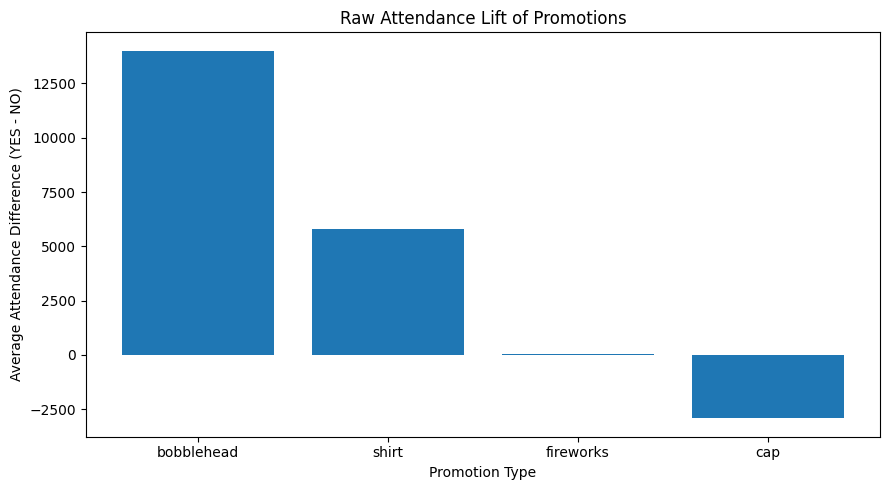

In [12]:

# Visualize the raw attendance lift from promotions.
plt.figure(figsize=(9, 5))
plt.bar(promotion_summary_df['promotion'], promotion_summary_df['raw_lift'])
plt.title('Raw Attendance Lift of Promotions')
plt.xlabel('Promotion Type')
plt.ylabel('Average Attendance Difference (YES - NO)')
plt.tight_layout()
plt.show()



### Story from the promotion analysis

The clearest pattern is the **bobblehead giveaway**. Games with a bobblehead promotion draw much larger crowds than games without one. Shirts also appear promising, but there are only a few shirt-promotion games in the data, so that result is less stable. Fireworks are harder to interpret because they mostly occur on Fridays, which already have their own attendance pattern.

At this point, the key management question becomes: **Does bobblehead still matter after controlling for other factors such as day of week, month, opponent, and weather?**


In [13]:

# Look at average attendance by opponent.
opponent_summary = (
    df.groupby('opponent')['attend']
      .agg(['count', 'mean'])
      .sort_values('mean', ascending=False)
)

opponent_summary.head(10).round(1)


,count,mean
opponent,,
Angels,3,49777.3
Mets,4,49586.2
Nationals,3,49267.3
White Sox,3,46382.0
Cubs,3,44206.7
Padres,9,42092.2
Phillies,3,41897.0
Cardinals,7,40853.3
Marlins,3,40665.3



### Opponent effect

Some opponents clearly attract more interest than others. Games against stronger or more recognizable opponents may naturally produce better attendance. This is another reason a multivariable model is useful: it helps separate promotion effects from opponent-driven demand.


In [15]:
# Build a multiple linear regression model without statsmodels.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split

# Define predictors and target.
X = df[['month', 'day_of_week', 'opponent', 'temp', 'skies',
        'day_night', 'cap', 'shirt', 'fireworks', 'bobblehead']]
y = df['attend']

# Convert categorical variables into dummy variables.
X_encoded = pd.get_dummies(X, drop_first=True)

# Split data into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# Fit the model.
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions.
y_pred = model.predict(X_test)

# Display model performance.
print("Intercept:", model.intercept_)
print("R-squared (test set):", r2_score(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))

# Show coefficients.
coef_df = pd.DataFrame({
    'Feature': X_encoded.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

print(coef_df)

Intercept: 20783.96567941268
R-squared (test set): 0.10450428924767619
Mean Absolute Error: 7345.84833458774
                  Feature   Coefficient
9      day_of_week_Sunday  24185.049188
11    day_of_week_Tuesday  22859.374033
8    day_of_week_Saturday  19645.540079
33          fireworks_YES  18805.986180
3               month_JUN  18257.865390
21     opponent_Nationals  16887.590990
10   day_of_week_Thursday  16223.717332
1               month_AUG  16031.902118
12  day_of_week_Wednesday  15225.897167
5               month_OCT  13473.197858
2               month_JUL  13081.750734
7      day_of_week_Monday  13010.769976
6               month_SEP  10363.284427
34         bobblehead_YES  10083.866343
4               month_MAY   8054.289074
14        opponent_Braves   3340.170891
16     opponent_Cardinals   2626.709616
23      opponent_Phillies   2509.236916
22        opponent_Padres   1953.912787
17          opponent_Cubs   1246.488849
29           skies_Cloudy   1072.348600
15       op

In [17]:
# Create a clean coefficient table (sklearn version)
coef_table = pd.DataFrame({
    'Feature': X_encoded.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

# Display top features
coef_table.round(3).head(15)

,Feature,Coefficient
9,day_of_week_Sunday,24185.049
11,day_of_week_Tuesday,22859.374
8,day_of_week_Saturday,19645.540
33,fireworks_YES,18805.986
3,month_JUN,18257.865
21,opponent_Nationals,16887.591
10,day_of_week_Thursday,16223.717
1,month_AUG,16031.902
12,day_of_week_Wednesday,15225.897
5,month_OCT,13473.198


## Interpretation of the regression model

The model is a weak fit. On the held-out test set it explains about 10% of the variation in attendance (R² ≈ 0.10), and its mean absolute error (about 7,300) is close to the standard deviation of attendance (about 8,300). Treat the coefficients as directional, not as reliable effect sizes.

Within that limit:
- **Bobblehead** games have a positive coefficient (about +10,000), and the raw averages point the same way (about 53,100 on 11 bobblehead games vs. about 39,100 on 70 others). It is not the largest coefficient in the model: fireworks, several weekdays, and some opponents are larger. The bobblehead estimate also rests on 11 games.
- **Day of week** has large coefficients. Sunday, Tuesday, and Saturday are above the baseline, and Monday and Wednesday are among the lowest weekday averages.
- **Caps** and **shirts** have very few games (2 and 3), so their estimates are not stable.

Bobbleheads were not given away on any Monday or Wednesday in this data. Every bobblehead game fell on a Tuesday, Thursday, Friday, Saturday, or Sunday. Any claim about bobbleheads on Monday or Wednesday is therefore an extrapolation, not something this data shows.

In [18]:

# Quantify the weakest and strongest days for a practical recommendation.
day_means = (
    df.groupby('day_of_week')['attend']
      .mean()
      .reindex(ordered_days)
)

day_means.round(1)


day_of_week
Monday       34965.7
Tuesday      47741.2
Wednesday    37585.2
Thursday     40407.4
Friday       40116.9
Saturday     43072.9
Sunday       42268.8
Name: attend, dtype: float64

In [19]:

# Compare bobblehead nights versus non-bobblehead nights on days where bobbleheads occur.
bobblehead_by_day = (
    df.groupby(['day_of_week', 'bobblehead'])['attend']
      .mean()
      .unstack()
)

bobblehead_by_day.round(1)


bobblehead,NO,YES
day_of_week,,
Friday,40116.9,NaN
Monday,34965.7,NaN
Saturday,41062.9,54128.0
Sunday,41178.0,55359.0
Thursday,32803.3,51813.5
Tuesday,43326.7,52891.5
Wednesday,37585.2,NaN


## Recommendation to Dodgers management

The data supports a narrower recommendation than the first draft made:

### Test bobblehead promotions on weekday games before scaling them up.

### What the data supports
1. **Bobblehead games drew more fans in this season.** Across 11 games, the average was about 14,000 higher than on other games. Within the same weekday, bobblehead games were higher in every case, but several of those comparisons rest on one or two games.
2. **Monday and Wednesday are the weakest attendance days** (about 35,000 and 37,600 on average, versus about 47,700 on Tuesdays).

### What the data does not support
- That bobbleheads would lift Monday or Wednesday crowds. None were held on those days, so the effect there is unknown.
- That bobbleheads are the single strongest driver. Other factors have larger coefficients, and the model explains little of the variation.

### Practical action plan
- Run a controlled test: schedule bobblehead giveaways on a few Monday or Wednesday games, and compare them with similar games that have no giveaway.
- Record ticket pricing, promotion cost, and opponent for each game, so the test can separate the promotion from the opponent and the schedule.
- Keep fireworks and other promotions in the data as separate factors, since the model cannot tell apart their effect and the day of the week.

## Conclusion

Attendance in this 2022 sample varies with the day of the week and the month, and the 11 bobblehead games drew more fans than the others. Those are associations in one season of one team, and the model explains only about 10% of attendance variation. The recommendation is to test bobbleheads on weekday games, including Mondays and Wednesdays, with a controlled comparison before committing budget to them. Ticket pricing, team performance, and marketing spend are needed to estimate the return on any promotion.